# A simple non-Poissonian example

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os
# sys.path.append("/group/hepheno/heptools/Fermi-NPTF-exposure/") 
sys.path.append("/group/hepheno/smsharma/NPTFit/Full_Testing/")

import copy
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp

# import fermi.fermi_plugin as fp  #module for loading templates needed for scan
import bayesian_scan_models_sid as bsms #module for performing scan
# import analysis_classes.fermi_analysis as fa  #module for analysing san

%matplotlib inline

## Define the directories and physics variables for the scan

In [2]:
work_dir = '/group/hepheno/smsharma/NPTFit/Full_Testing'  #chains, plots, and data folders created here
maps_dir = '/mnt/hepheno/CTBCORE/'  #should contain data, unless otherwise specificed, along with other relevant data files, such as PSF fits files
psf_dir = '/mnt/hepheno/CTBCORE/psf_data' #directory where to save rho(f) files for taking into account PSF in NPTF
fermi_data_dir = '/mnt/hepheno/FermiData/'

In [3]:
tag = 'Example'
run_tag = 'IG_NPTF_en_8_16' 

In [4]:
CTB_en_min = 8
CTB_en_max=16
nside=128

In [5]:
band_mask_range =  [-2.,2.]  
mask_ring = True
outer=30  

In [6]:
mask_type = '0.95' 
force_energy = True 
energy_bin_mask = 8 

In [7]:
data_name = 'p8'
newstyle = 1
eventclass = 5
eventtype = 3

## Now we will make an instance of bayesian_scan_models to setup the template scan

### Setting up the scan

In [8]:
iso_temp = [np.load("../../Fermi_Data/Template_iso.npy")]
diff_temp = [np.load("../../Fermi_Data/Template_dif.npy")]

In [9]:
fermi_data = np.load("../../Fermi_Data/FermiData_counts.npy")
fermi_exposure = np.load("../../Fermi_Data/FermiData_exposure.npy")
fermi_psc_mask = np.load("../../Fermi_Data/FermiData_pscmask.npy")

In [10]:
b = bsms.bayesian_scan_NPTF(tag=tag,nside=nside,work_dir=work_dir,psf_dir=psf_dir)
b.load_external_data([8,16], [fermi_data], [fermi_exposure])
b.make_mask_total(band_mask_range =  band_mask_range,mask_ring = mask_ring,outer=outer)

In [11]:
temp_dict = {'iso': iso_temp, 'diff': diff_temp}

In [12]:
b.add_new_template(temp_dict)
b.rebin_external_data(1)

Now let's add our Poissonian models

In [13]:
b.add_poiss_model('diff','$A_{diff}$',[0,2],False)
b.add_poiss_model('iso','$A_{iso}$',[-2,2],False)

In [14]:
b.add_non_poiss_model('iso',['$\\tilde A_{ps}$','$n_1$','$n_2$','$S_b^{(1)}$'],[[-6,6],[2.05,30],[-2,1.95],[0.05,30]],[True,False,False,False])

Now, we will initiate the NPTF.  We have 2 PS templates, so we use `b.initiate_2_ps_edep`.  There are also functions for initializing 1 PS and 3 PS.

In [15]:
f_ary, df_ary = np.load("../../Full_Testing/psf_dir/gauss_128_0.181.npy")

In [16]:
b.initiate_ps_from_f_ary(f_ary, df_ary)

/group/hepheno/smsharma/NPTFit/Full_Testing/config_file.py:370: VisibleDeprecationWarning: using a non-integer number instead of an integer will result in an error in the future
  new_data_masked[mask_array[i]] = 1


$A_{diff}$
$A_{iso}$
0 [True, False, False, False]
1 [True, False, False, False]
2 [True, False, False, False]
3 [True, False, False, False]
The k_max_array is  [4463.0]
The number of parameters is  6


### Running the scan

In [ ]:
b.perform_scan(run_tag=run_tag)

/group/hepheno/smsharma/NPTFit/Full_Testingchains/Example/IG_NPTF_en_8_16/


## Analysis

In [ ]:
outer_plot=10 #this is the outer radius for the spectrum analysis
kwargs_spectrum={ 'band_mask_range': band_mask_range,'mask_ring': mask_ring, 'outer': outer_plot}

In [99]:
cs=fa.compute_edep_spectra(b,run_tag,b.CTB_en_bins,**kwargs_spectrum)

In [100]:
print 'nfw PS: ', cs.return_intensity_arrays_non_poiss('nfw',0)
print 'disk PS: ', cs.return_intensity_arrays_non_poiss('disk',0)

nfw PS:  [  4.70739617e-07   5.34225279e-07   5.99611601e-07]
disk PS:  [  3.58172576e-08   5.60208218e-08   8.13198316e-08]


In [82]:
print 'p6: ',cs.cs_array[0].return_poiss_intensity_conf_int('p6-0',quant = [0.16,0.5,0.84])
print 'bubs: ',cs.cs_array[0].return_poiss_intensity_conf_int('bubs-0',quant = [0.16,0.5,0.84])
print 'nfw: ',cs.cs_array[0].return_poiss_intensity_conf_int('nfw-0',quant = [0.16,0.5,0.84])

p6:  at comp  p6-0 log prior:  False intensity:  [  5.57272524e-06   5.61123997e-06   5.64570734e-06]
[  5.57272524e-06   5.61123997e-06   5.64570734e-06]
bubs:  at comp  bubs-0 log prior:  False intensity:  [  1.87734362e-07   1.98366400e-07   2.09327907e-07]
[  1.87734362e-07   1.98366400e-07   2.09327907e-07]
nfw:  at comp  nfw-0 log prior:  True intensity:  [  2.37629410e-12   8.08709913e-11   2.88601198e-09]
[  2.37629410e-12   8.08709913e-11   2.88601198e-09]


In [46]:
b.calculate_medians()

the medians are  [ -3.73141059   1.05706672   0.98297275   1.00177935  -0.50270014
  17.88364845  -1.13807972   9.87789762  -3.33149004  14.3832542
  -0.56090738  24.66156355]
the medians (from chains) are  [ -3.73141059   1.05706672   0.98297275   1.00177935  -0.50270014
  17.88364845  -1.13807972   9.87789762  -3.33149004  14.3832542
  -0.56090738  24.66156355]
the number of parameters is  12


### PS-specific analyses: source-count function

#### 1.  The 3FGL sources

In [33]:
only_gal=True
flux_min=1e-11 #photons/cm^2/s/sr
flux_max=1e-8
n_flux_bins=15
error_range=0.68 #for plotting uncertanties

In [34]:
p3FGL = fa.plot_3FGL(f,only_gal=False,CTB_en_min=b.CTB_en_min,CTB_en_max=b.CTB_en_max,**kwargs_spectrum)

8 16
0 8


In [35]:
p3FGL.configure_3FGL(flux_min=flux_min,flux_max=flux_max,n_flux_bins = n_flux_bins,error_range = error_range)   

#### 2.  The best-fit dN/dS

In [36]:
pdnds = fa.plot_dnds(b,**kwargs_spectrum)

#### 3.  Plot $dN / dF$

In [103]:
from matplotlib import rcParams

rcParams['text.usetex']=True
rcParams['xtick.labelsize'] = 16
rcParams['ytick.labelsize'] = 16
rcParams['axes.labelsize']=18
rcParams['axes.titlesize']=18
rcParams['font.family']='serif'
rcParams['font.serif']='CMU Serif'

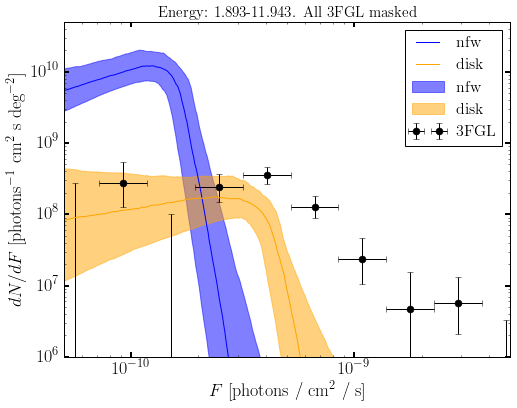

In [106]:
plt.figure(figsize=(8,6))
#plot medians
pdnds.plot_source_count_median('nfw',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='blue',label='nfw')
pdnds.plot_source_count_median('disk',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='orange',label='disk')

#plot band
pdnds.plot_source_count_band('nfw',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='blue',label='nfw',alpha=0.5)
pdnds.plot_source_count_band('disk',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='orange',label='disk',alpha=0.5)

#also show 3FGL
p3FGL.plot_3FGL(fmt = 'o', color='black',markersize=7,label='3FGL')

plt.legend(fontsize=16) 

plt.yscale('log')
plt.xscale('log')
plt.xlim([5e-11,5e-9])
plt.ylim([1e6,5e10])

plt.tick_params(axis='x', length=5,width=2,labelsize=18)
plt.tick_params(axis='y',length=5,width=2,labelsize=18)
plt.xlabel('$F$  [photons / cm$^2$ / s]', fontsize=18)
plt.ylabel('$dN/dF$  [photons$^{-1}$ cm$^2$ s deg$^{-2}$]', fontsize=18)

plt.title('Energy: '+str(np.round(b.CTB_en_bins[0],3)) + '-'+str(np.round(b.CTB_en_bins[0+1],3))+ '.  All 3FGL masked',fontsize=15)
plt.savefig("NPTF.pdf")